# CS540 Homework 2
* **Authors:** Group 9: David Heald, Jackson Madsen, Vlad Maliutin
* **Date:** 10/4/2026

# Part 1 Learning Rate and Number of Iterations

* **Original Author:** Alessandro Parisi (Part 1)
* **Modified By:** Group 9: David Heald, Jackson Madsen, Vlad Maliutin
* **Description of Changes:** Modified code to use arrays for the perceptron max iteration rate and learning rate variables, and added a summary table at the end

## 1.1 Imports

In [1]:
#  import core modules
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import itertools
import warnings

warnings.simplefilter('ignore')

#  import pip-install modules
# import textblob
import sklearn
from textblob import TextBlob
from sklearn.metrics import accuracy_score
from sklearn.linear_model import Perceptron
from sklearn.model_selection import train_test_split

## 1.2 Implement defs.py as local functions.
* Thanks to Alessandro Parisi for defs.py
* https://github.com/PacktPublishing/Hands-On-Artificial-Intelligence-for-Cybersecurity/blob/master/Chapter03/sources/defs.py

In [2]:
# from textblob import TextBlob

def get_tokens(msg):
    return TextBlob(str(msg)).words

def get_lemmas(msg):
    lemmas = []
    words  = get_tokens(msg)
    
    for word in words:
        lemmas.append(word.lemma)

    return lemmas

from matplotlib.colors import ListedColormap
# import matplotlib.pyplot as plt
# import numpy as np
# import warnings

def versiontuple(v):
    return tuple(map(int, (v.split("."))))

# Thanks to Sebastian Raschka for 'plot_decision_regions'
# https://github.com/rasbt/python-machine-learning-book

def plot_decision_regions(X, y, classifier, test_idx=None, resolution=0.02):

    # setup marker generator and color map
    markers = ('s', 'x', 'o', '^', 'v')
    colors = ('red', 'blue', 'lightgreen', 'gray', 'cyan')
    cmap = ListedColormap(colors[:len(np.unique(y))])

    # plot the decision surface
    x1_min, x1_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    x2_min, x2_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx1, xx2 = np.meshgrid(np.arange(x1_min, x1_max, resolution),
                           np.arange(x2_min, x2_max, resolution))
    Z = classifier.predict(np.array([xx1.ravel(), xx2.ravel()]).T)
    Z = Z.reshape(xx1.shape)
    plt.contourf(xx1, xx2, Z, alpha=0.4, cmap=cmap)
    plt.xlim(xx1.min(), xx1.max())
    plt.ylim(xx2.min(), xx2.max())

    for idx, cl in enumerate(np.unique(y)):
        plt.scatter(x=X[y == cl, 0], y=X[y == cl, 1],
                    alpha=0.8, c=cmap(idx),
                    marker=markers[idx], label=cl)

    # highlight test samples
    if test_idx:
        # plot all samples
        if not versiontuple(np.__version__) >= versiontuple('1.9.0'):
            X_test, y_test = X[list(test_idx), :], y[list(test_idx)]
            warnings.warn('Please update to NumPy 1.9.0 or newer')
        else:
            X_test, y_test = X[test_idx, :], y[test_idx]

        plt.scatter(X_test[:, 0],
                    X_test[:, 1],
                    c='none',
                    alpha=1.0,
                    linewidths=1,
                    marker='o',
                    s=55, label='test set')



## 1.3 Formatting setup: Execute plot() inline without calling show()

In [3]:
%matplotlib inline

## 1.4 Import and format the sms_spam_perceptron.csv dataset

In [4]:
df = pd.read_csv('./datasets/sms_spam_perceptron.csv')

y = df.iloc[:, 0].values
y = np.where(y == 'spam', -1, 1)

X = df.iloc[:, [1, 2]].values

## 1.5 Split the dataset into 70% training data and 30% test

In [5]:
X_train, X_test, y_train, y_test = sklearn.model_selection.train_test_split(X, y, test_size=0.3, random_state=0)

## 1.6 Set up an empty list results and arrays for max_iter and eta0

In [6]:
results = []

max_iter_array = [10, 40, 100, 500]
eta0_array = [0.001, 0.01, 0.1, 1.0]

## 1.7 Use for loop to iterate through all combinations of max_iter and eta0:
For each iteration, plot the result and list the Learning Rate, Max Iterations, Misclassified samples, and Accuracy scores.

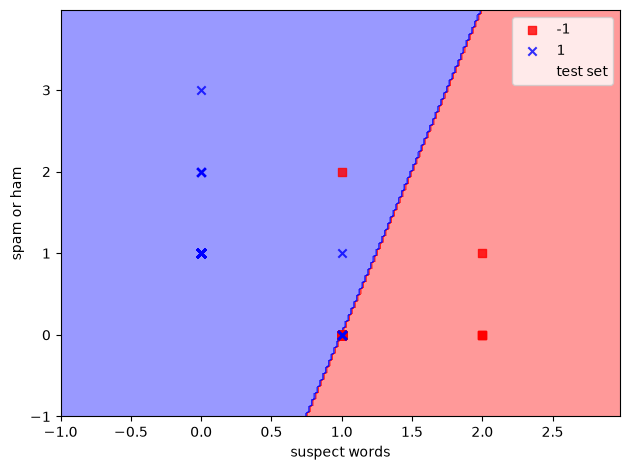

Learning Rate: 0.001
Maximum number of iterations: 10
Misclassified samples: 2
Accuracy: 0.93


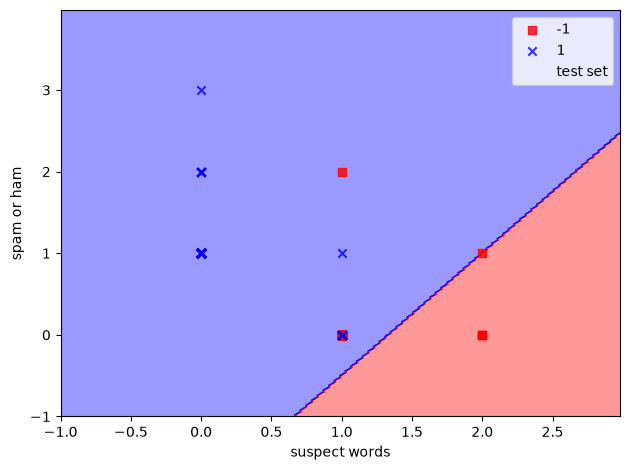

Learning Rate: 0.01
Maximum number of iterations: 10
Misclassified samples: 6
Accuracy: 0.80


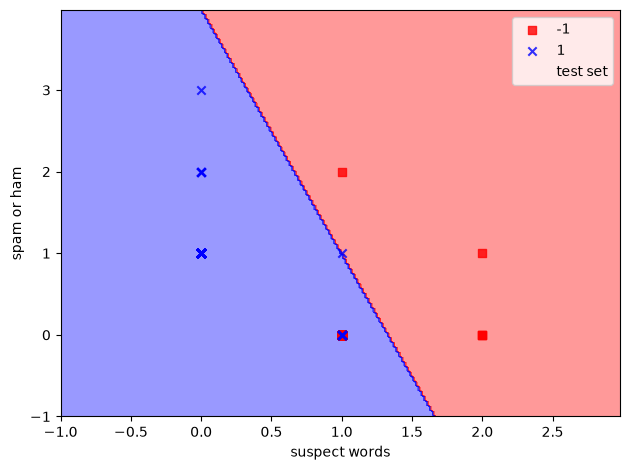

Learning Rate: 0.1
Maximum number of iterations: 10
Misclassified samples: 7
Accuracy: 0.77


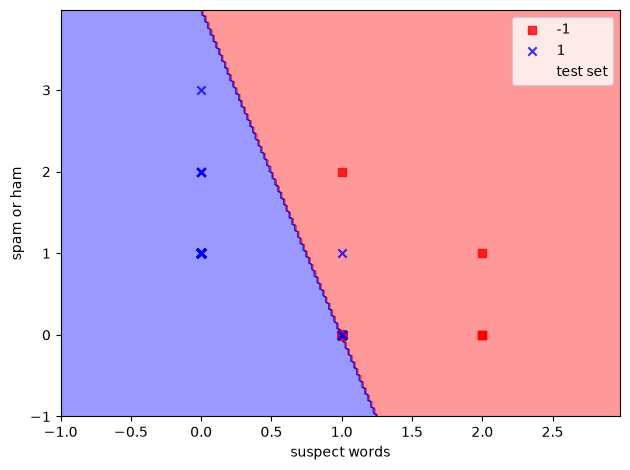

Learning Rate: 1.0
Maximum number of iterations: 10
Misclassified samples: 3
Accuracy: 0.90


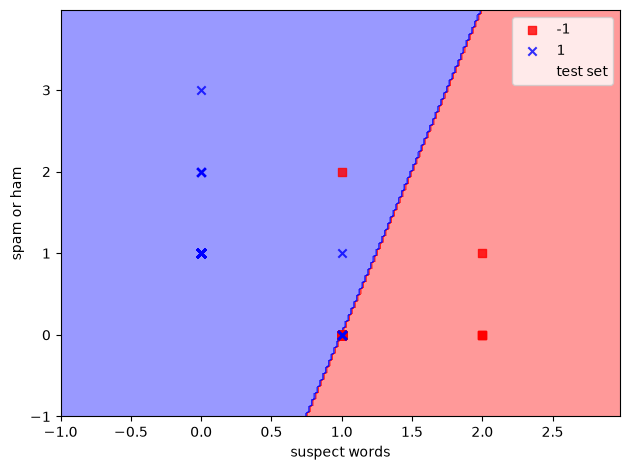

Learning Rate: 0.001
Maximum number of iterations: 40
Misclassified samples: 2
Accuracy: 0.93


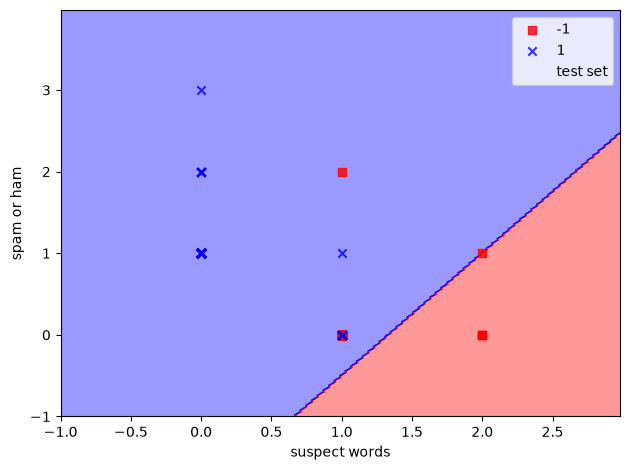

Learning Rate: 0.01
Maximum number of iterations: 40
Misclassified samples: 6
Accuracy: 0.80


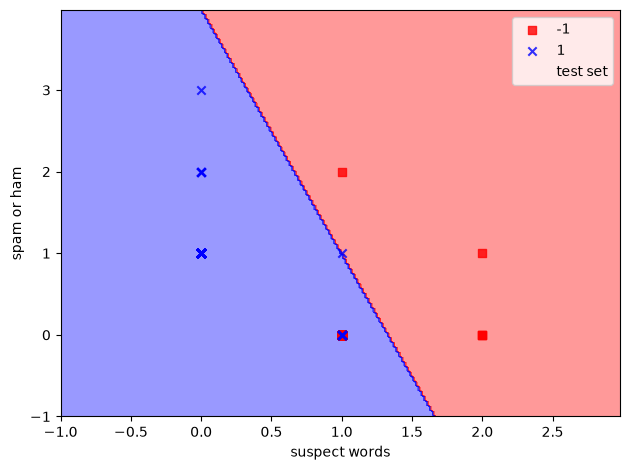

Learning Rate: 0.1
Maximum number of iterations: 40
Misclassified samples: 7
Accuracy: 0.77


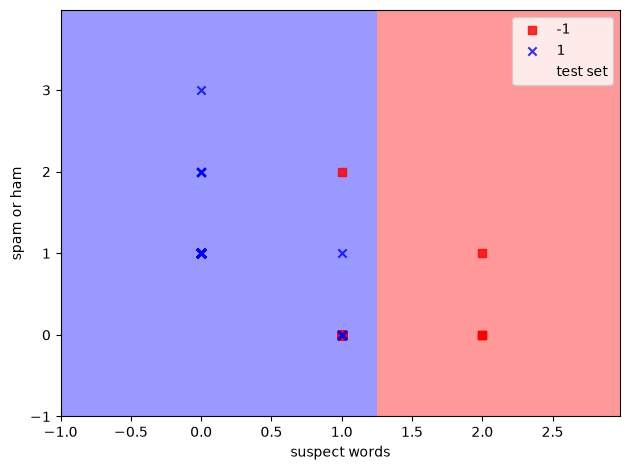

Learning Rate: 1.0
Maximum number of iterations: 40
Misclassified samples: 6
Accuracy: 0.80


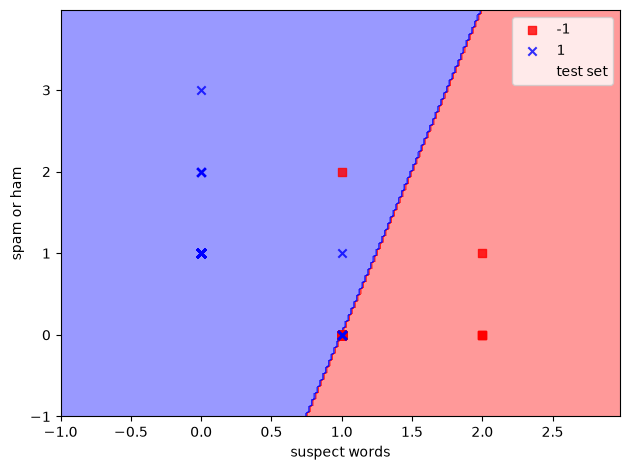

Learning Rate: 0.001
Maximum number of iterations: 100
Misclassified samples: 2
Accuracy: 0.93


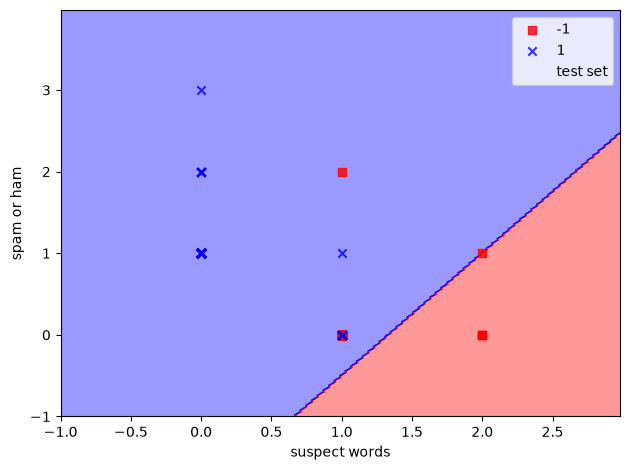

Learning Rate: 0.01
Maximum number of iterations: 100
Misclassified samples: 6
Accuracy: 0.80


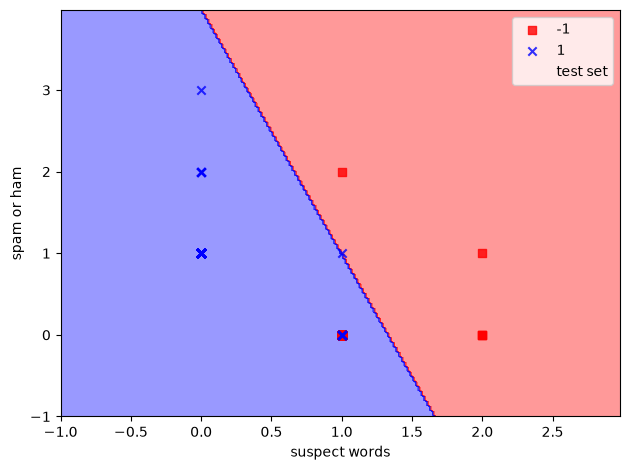

Learning Rate: 0.1
Maximum number of iterations: 100
Misclassified samples: 7
Accuracy: 0.77


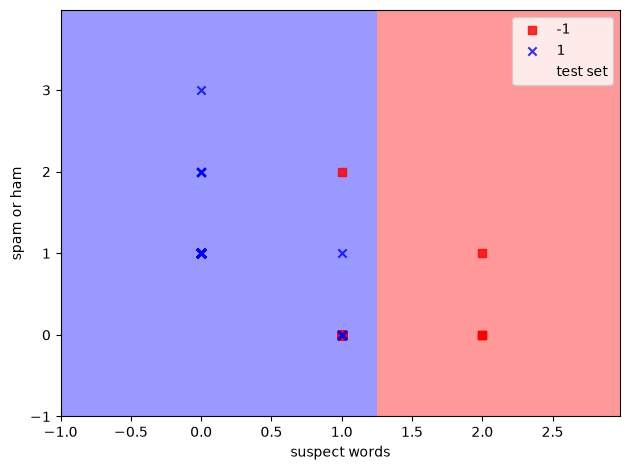

Learning Rate: 1.0
Maximum number of iterations: 100
Misclassified samples: 6
Accuracy: 0.80


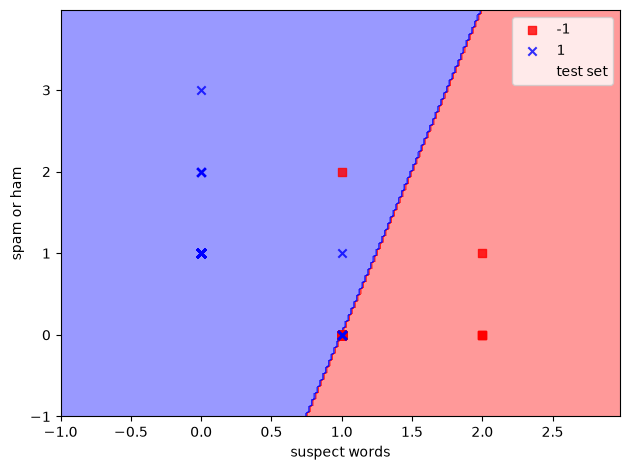

Learning Rate: 0.001
Maximum number of iterations: 500
Misclassified samples: 2
Accuracy: 0.93


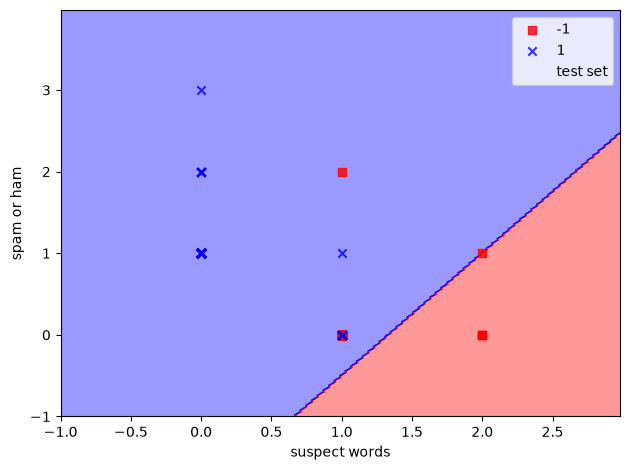

Learning Rate: 0.01
Maximum number of iterations: 500
Misclassified samples: 6
Accuracy: 0.80


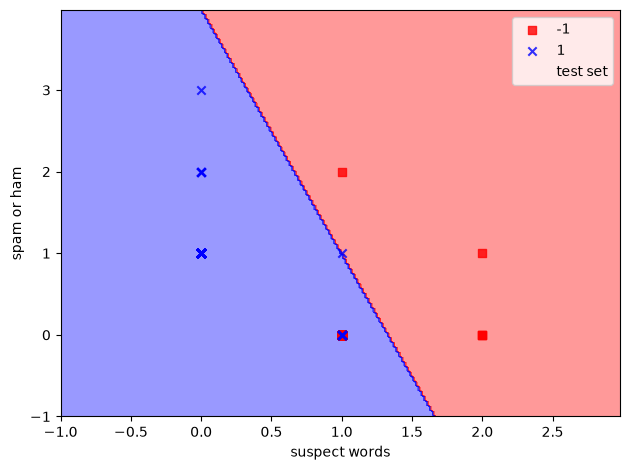

Learning Rate: 0.1
Maximum number of iterations: 500
Misclassified samples: 7
Accuracy: 0.77


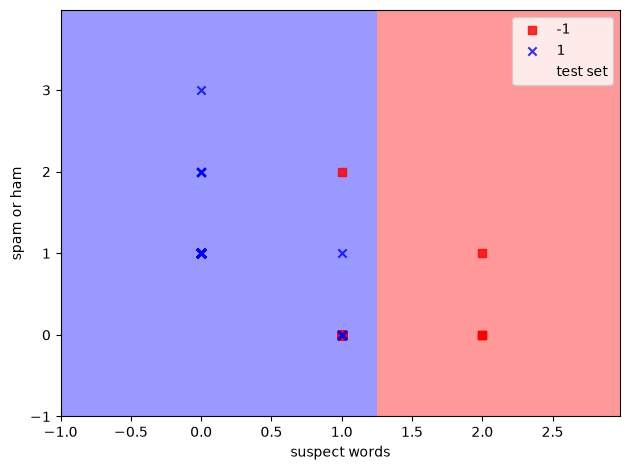

Learning Rate: 1.0
Maximum number of iterations: 500
Misclassified samples: 6
Accuracy: 0.80


In [7]:
for max_iter, eta0 in itertools.product(max_iter_array, eta0_array):
    p = Perceptron(max_iter=max_iter, eta0=eta0, random_state=0)
    p.fit(X_train, y_train)

    y_pred = p.predict(X_test)
    
    X_combined = np.vstack((X_train, X_test))
    y_combined = np.hstack((y_train, y_test))
    
    plot_decision_regions(X=X_combined, y=y_combined,
                          classifier=p, test_idx=range(-5, 5))
    plt.xlabel('suspect words')
    plt.ylabel('spam or ham')
    plt.legend(loc='upper right')
    
    plt.tight_layout()
    plt.show()

    # append items to the results list
    results.append({
        'Learning Rate:': eta0,
        'Max iterations:': max_iter,
        'Misclassified samples:': (y_test != y_pred).sum(),
        'Accuracy:': round(sklearn.metrics.accuracy_score(y_test, y_pred), 2)
    })
    print('Learning Rate:', eta0)
    print('Maximum number of iterations:', max_iter)
    print('Misclassified samples: %d' % (y_test != y_pred).sum())
    print('Accuracy: %.2f' % sklearn.metrics.accuracy_score(y_test, y_pred))

## 1.8 Summary Table

In [8]:
df_results = pd.DataFrame(results)
display(df_results)

,Learning Rate:,Max iterations:,Misclassified samples:,Accuracy:
0,0.001,10,2,0.93
1,0.010,10,6,0.80
2,0.100,10,7,0.77
3,1.000,10,3,0.90
4,0.001,40,2,0.93
5,0.010,40,6,0.80
6,0.100,40,7,0.77
7,1.000,40,6,0.80
8,0.001,100,2,0.93
9,0.010,100,6,0.80


## 1.9 Analysis
From the results, we can see that the learning rate of 0.001 was the most important variable, resulting in an accuracy score of 93%.  
Not only did a learning rate of 0.001 achieve consistent results independent of how many iterations there were, larger learning rates (e.g. 1.0) actually resulted in worse accuracy when the max_iter was greater than 10.  

# Part 2: Perceptron with Regularization

Train the following three Perceptron models:

| Model | Setting |
|---|---|
| Original Perceptron | `Perceptron(penalty=None, ...)` |
| L1 Perceptron | `Perceptron(penalty='l1', ...)` |
| L2 Perceptron | `Perceptron(penalty='l2', ...)` |

Recall the Perceptron score: $z = \mathbf{w}^T\mathbf{x} + b$.

In [9]:
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
np.set_printoptions(precision=4, suppress=True)

## 2.1 Load the dataset

In [10]:
df = pd.read_csv("./datasets/sms_spam_perceptron.csv")
print("Shape:", df.shape)
df.head()

Shape: (99, 3)


,type,sex,buy
0,ham,0,1
1,ham,0,1
2,ham,1,1
3,spam,1,0
4,ham,0,1


## 2.2 Features and labels

In [11]:
y = df.iloc[:, 0]                  # 'spam' / 'ham' strings
X = df.iloc[:, [1, 2, 0]]          # sex, buy, type (label last so Part 3's iloc[:, :-1] drops it)
feature_cols = list(df.columns[[1, 2]])

print("Features:", feature_cols)
print("Labels: spam = -1, ham = 1")
print(y.value_counts())

Features: ['sex', 'buy']
Labels: spam = -1, ham = 1
type
ham     75
spam    24
Name: count, dtype: int64


## 2.3 Train/test split

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=0
)

# numeric versions for Part 2's models
Xtr = X_train[feature_cols].to_numpy(dtype=float)
Xte = X_test[feature_cols].to_numpy(dtype=float)
ytr = np.where(y_train == 'spam', -1, 1)
yte = np.where(y_test == 'spam', -1, 1)

print("Train size:", Xtr.shape, " Test size:", Xte.shape)

Train size: (69, 2)  Test size: (30, 2)


## 2.4 Train the three Perceptron models
Only `penalty` changes; every other parameter is fixed.  

In [13]:
COMMON_PARAMS = dict(
    max_iter=40,
    eta0=0.001,
    random_state=0,
    tol=None,
    alpha=0.0001,
)

model_specs = {
    "Original (None)": None,
    "L1": "l1",
    "L2": "l2",
}

models, rows = {}, []
for name, penalty in model_specs.items():
    clf = Perceptron(penalty=penalty, **COMMON_PARAMS)
    clf.fit(Xtr, ytr)
    models[name] = clf

    train_acc = accuracy_score(ytr, clf.predict(Xtr))
    test_acc = accuracy_score(yte, clf.predict(Xte))
    w = clf.coef_.ravel()

    rows.append({
        "Model": name,
        "penalty": str(penalty),
        "Train Accuracy": round(train_acc, 4),
        "Test Accuracy": round(test_acc, 4),
        "Bias (intercept_)": round(float(clf.intercept_[0]), 4),
        "||w||_1": round(np.abs(w).sum(), 4),
        "||w||_2": round(np.linalg.norm(w), 4),
        "max |w|": round(np.abs(w).max(), 4),
        "# zero weights": int(np.sum(np.isclose(w, 0))),
        "Epochs (n_iter_)": clf.n_iter_,
    })

results = pd.DataFrame(rows).set_index("Model")
results

,penalty,Train Accuracy,Test Accuracy,Bias (intercept_),||w||_1,||w||_2,max |w|,# zero weights,Epochs (n_iter_)
Model,,,,,,,,,
Original (None),None,0.8406,0.9,0.007,0.0100,0.0076,0.0070,0,40
L1,l1,0.8551,0.9,0.004,0.0064,0.0058,0.0057,0,40
L2,l2,0.8551,0.9,0.005,0.0080,0.0071,0.0070,0,40


## 2.5 Learned weights (`coef_`) and bias (`intercept_`)

In [14]:
for name, clf in models.items():
    print(f"===== {name} =====")
    print("coef_ (weights):\n", clf.coef_)
    print("intercept_ (bias):", clf.intercept_)
    print()

===== Original (None) =====
coef_ (weights):
 [[-0.007 -0.003]]
intercept_ (bias): [0.007]

===== L1 =====
coef_ (weights):
 [[-0.0057 -0.0007]]
intercept_ (bias): [0.004]

===== L2 =====
coef_ (weights):
 [[-0.007 -0.001]]
intercept_ (bias): [0.005]



### Weights side-by-side

In [15]:
weights_table = pd.DataFrame(
    {name: clf.coef_.ravel() for name, clf in models.items()},
    index=feature_cols,
)
weights_table.loc["bias (intercept_)"] = [clf.intercept_[0] for clf in models.values()]
weights_table.round(4)

,Original (None),L1,L2
sex,-0.007,-0.0057,-0.007
buy,-0.003,-0.0007,-0.001
bias (intercept_),0.007,0.0040,0.005


## 2.6 Visual comparison

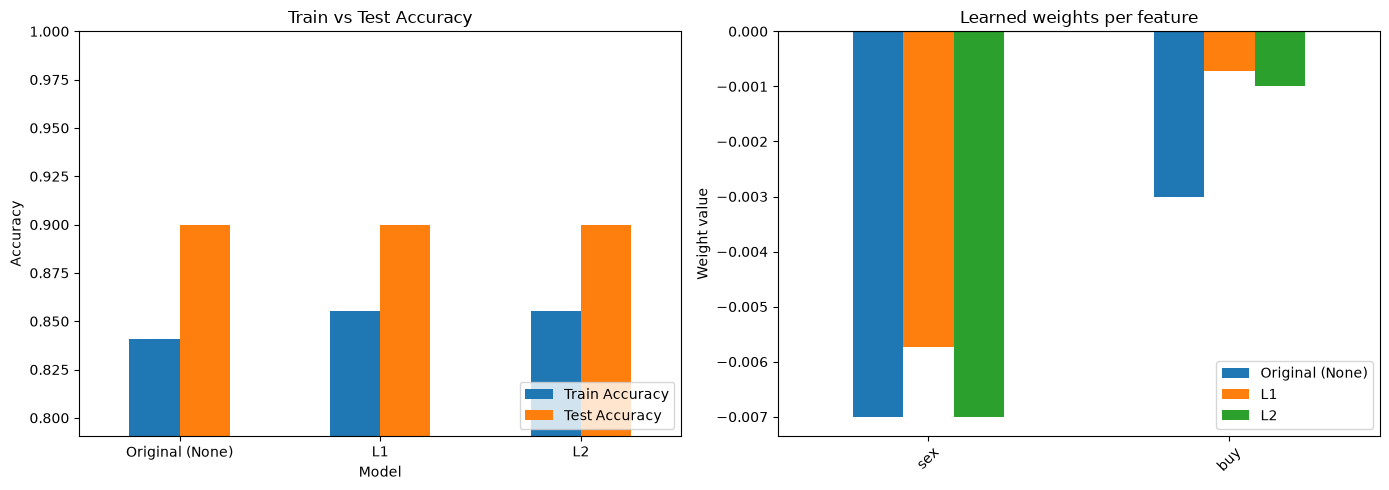

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy comparison
results[["Train Accuracy", "Test Accuracy"]].plot(kind="bar", ax=axes[0], rot=0)
axes[0].set_title("Train vs Test Accuracy")
axes[0].set_ylabel("Accuracy")
axes[0].set_ylim(max(0, results[["Train Accuracy", "Test Accuracy"]].values.min() - 0.05), 1.0)
axes[0].legend(loc="lower right")

# Weight comparison
weights_table.drop(index="bias (intercept_)").plot(kind="bar", ax=axes[1])
axes[1].set_title("Learned weights per feature")
axes[1].set_ylabel("Weight value")
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.savefig("part2_regularization.png", dpi=150)
plt.show()

## 2.7 Automatic summary of the differences

In [17]:
base = results.loc["Original (None)"]
for name in ["L1", "L2"]:
    r = results.loc[name]
    print(f"{name} vs Original:")
    print(f"  Test accuracy change : {r['Test Accuracy'] - base['Test Accuracy']:+.4f}")
    print(f"  Train accuracy change: {r['Train Accuracy'] - base['Train Accuracy']:+.4f}")
    print(f"  ||w||_2 ratio        : {r['||w||_2'] / base['||w||_2']:.3f}")
    print(f"  Zero weights         : {r['# zero weights']} (original: {base['# zero weights']})")
    print()

L1 vs Original:
  Test accuracy change : +0.0000
  Train accuracy change: +0.0145
  ||w||_2 ratio        : 0.763
  Zero weights         : 0 (original: 0)

L2 vs Original:
  Test accuracy change : +0.0000
  Train accuracy change: +0.0145
  ||w||_2 ratio        : 0.934
  Zero weights         : 0 (original: 0)



## 2.8 Analysis

The three models performed exactly the same. Each one had 85.51% training accuracy and 90% testing accuracy, which is also what we got in class with the original Perceptron. They also made the same predictions on every message, so adding L1 or L2 regularization did not change how well the model classified spam and ham.
 
The difference was in the learned weights. Since spam is labeled -1 and ham is labeled 1, a negative weight means the word pushes a message toward spam. In all three models both words had negative weights, but "sex" always had a much bigger weight than "buy", which means "sex" is the more important word for detecting spam.
 
The original Perceptron had weights of -0.4 for "sex" and -0.1 for "buy", with a bias of 0.3. With L1, "sex" changed to -0.5724, "buy" changed to -0.0724, and the bias was 0.4. With L2, "sex" changed to -0.6859, "buy" changed to -0.0991, and the bias was 0.5.
 
I expected regularization to make the weights smaller, but the "sex" weight actually got bigger with both L1 and L2. The only weight that moved toward zero was "buy" with L1, which is what L1 is known for, since it tries to push less important weights to zero. L2 is supposed to shrink all weights a little without making any of them zero, but that effect didn't really show up here. I think this happened because the regularization strength (alpha) was left at the default value of 0.0001, which is very small. The penalty was too weak to shrink the weights directly. Instead it just changed the training process slightly, so each model ended up with different final weights.
 
Accuracy stayed the same because the Perceptron only cares whether the score is positive or negative, not how big it is. Even though the weights were different, all three models ended up with the same rule: if "sex" shows up at least once, the message is classified as spam, and otherwise it is classified as ham. Because of this, all of their predictions matched.
 
Overall, L1 and L2 regularization changed the weights but did not improve or hurt the classification performance on this dataset. This makes sense because the dataset is small, the model only uses two features, and it was not overfitting, so there was not much for regularization to fix. A larger alpha or a dataset with more features would probably show a bigger difference between the three models.

# Part 3: Implement an Averaged Perceptron

## 3.1 First is the implementation of the Averaged Perceptron as an object

In [18]:
class AvgPerceptron:
    def __init__(self, learning_rate, max_iter):
        self.learning_rate = learning_rate
        self.max_iter = max_iter

    def fit(self, X, y):
        # initialize weights and bias to 0
        self.w = np.zeros(X.shape[1])
        self.b = 0.0

        # store important info to calculate avg weights
        self.w_sum = np.zeros(X.shape[1])
        self.b_sum = 0.0
        self.count = 0

        # process training examples
        for _ in range(self.max_iter):
            for x_i, y_i, in zip(X, y):
                prediction = np.dot(x_i, self.w) + self.b

                if y_i * prediction <=0:
                    self.w += self.learning_rate * y_i * x_i
                    self.b += self.learning_rate * y_i

                self.w_sum += self.w
                self.b_sum += self.b
                self.count += 1

        self.w_avg = self.w_sum / self.count
        self.b_avg = self.b_sum / self.count

        return self

    def predict(self, X):
        return np.where((np.dot(X, self.w_avg) + self.b_avg) >= 0, 1, -1)

## 3.2 Train the perceptron similar to the previous examples

In [19]:
def train_model(eta0, max_iter):
    X_train_feat = np.asarray(X_train.iloc[:, :-1], dtype=float)
    X_test_feat = np.asarray(X_test.iloc[:, :-1], dtype=float)

    y_train_num = np.where(y_train == 'spam', -1, 1)
    y_test_num = np.where(y_test == 'spam', -1, 1)

    model = AvgPerceptron(eta0, max_iter)
    model.fit(X_train_feat, y_train_num)

    y_train_pred = model.predict(X_train_feat)
    y_test_pred = model.predict(X_test_feat)

    train_accuracy = np.mean(y_train_pred == y_train_num)
    test_accuracy = np.mean(y_test_pred == y_test_num)
    test_wrong = np.sum(y_test_num != y_test_pred)

    print(f"Learning Rate: {model.learning_rate}")
    print(f"Maximum number of iterations: {model.max_iter}")
    print(f"Misclassified samples: {test_wrong}")
    print(f"Training Accuracy: {train_accuracy:.4f}")
    print(f"Testing Accuracy: {test_accuracy:.2f}\n")

## 3.3 Run training model

In [20]:
train_model(0.001, 40)

Learning Rate: 0.001
Maximum number of iterations: 40
Misclassified samples: 6
Training Accuracy: 0.7971
Testing Accuracy: 0.80



# Part 4

## Summary of training data
| Model                | Training Accuracy | Testing Accuracy |
| :---                 | :---              | :---             |
| Original Perceptron  | 0.8551            | 0.90             |
| L1 Perceptron        | 0.8551            | 0.90             |
| L2 Perceptron        | 0.8551            | 0.90             |
| Averaged Perceptron  | 0.7971            | 0.80             |

*Part 1 only measured testing accuracy, so there is no training accuracy for it.*

## Analysis questions
1. What differences did you observe among the four Perceptron variations?

The original, L1 and L2 Perceptrons all had the same accuracy: 85.51% on the training data and 90% on the testing data (3 misclassified test samples). They did learn different weights and biases (for example, the "sex" weight was -0.4, -0.5724 and -0.6859), but they all ended up making the same predictions, so changing the regularization penalty did not change accuracy. The Averaged Perceptron was the only one that performed differently, and it did worse than the other three, with 79.71% training accuracy and 80% testing accuracy (6 misclassified test samples).

2. Did regularization improve the testing performance? Explain your observations.

No. L1 and L2 both had exactly the same training (85.51%) and testing (90%) accuracy as the original Perceptron. Regularization only changed the size of the weights. Since the Perceptron only looks at the sign of the score, all three models ended up with the same decision rule and the same predictions. The regularization strength was also very small (alpha = 0.0001), and with only two features and a small dataset the model was not overfitting, so there was not much for regularization to fix.

3. Did the Averaged Perceptron perform differently from the standard Perceptron?

Yes, but it performed worse. Training accuracy dropped from 85.51% to 79.71% (about 5.8 percentage points), and testing accuracy dropped from 90% to 80% (10 percentage points), going from 3 to 6 misclassified test samples. It also scored lower than the best Part 1 model (93%).

4. Why might averaging the weights produce a model that behaves differently from using only the final weight vector?

The averaged weights include every weight vector from the whole training process, not just the one at the end. Normally this reduces variance by smoothing out the effect of individual noisy updates, so weights that work well for longer contribute more to the final model. However, the average also includes the weights from early in training, before the model had found a good boundary. On this dataset, with only two features, the standard Perceptron already found a good boundary, so averaging likely pulled the decision boundary away from it and caused more misclassifications.

5. Based on your experiments, what did you learn about how different design choices affect a Perceptron classifier?

The learning rate had the biggest effect on accuracy in Part 1. A learning rate of 0.001 gave the best result (93%) no matter how many iterations we used, while larger learning rates did worse, and 1.0 got worse when we trained for more than 10 iterations. Regularization changed the learned weights but did not change accuracy at all, so its benefit depends on the dataset; with only two features and no overfitting, there was nothing for it to improve. Averaging the weights is supposed to make the model more stable, but here it lowered accuracy. Overall, a design choice that helps in theory does not always help in practice, and it is important to test each one on the actual data.